In [2]:
%pip install pandas
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd

df = pd.read_csv("../data/raw/train.csv")
df.head()

,site_id,patient_id,image_id,laterality,view,age,cancer,biopsy,invasive,BIRADS,implant,density,machine_id,difficult_negative_case
0,2,10006,462822612,L,CC,61.0,0,0,0,NaN,0,NaN,29,False
1,2,10006,1459541791,L,MLO,61.0,0,0,0,NaN,0,NaN,29,False
2,2,10006,1864590858,R,MLO,61.0,0,0,0,NaN,0,NaN,29,False
3,2,10006,1874946579,R,CC,61.0,0,0,0,NaN,0,NaN,29,False
4,2,10011,220375232,L,CC,55.0,0,0,0,0.0,0,NaN,21,True


In [4]:
# Afficher les types de données
df.info()

# Calculer les valeurs manquantes
missing_values = df.isnull().sum()

# Calculer leur pourcentage
missing_percent = df.isnull().mean() * 100

# Construire un tableau récapitulatif
missing_summary = pd.DataFrame({
    "Missing values": missing_values,
    "Missing (%)": missing_percent.round(2)
})

display(missing_summary)

<class 'pandas.DataFrame'>
RangeIndex: 54706 entries, 0 to 54705
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   site_id                  54706 non-null  int64  
 1   patient_id               54706 non-null  int64  
 2   image_id                 54706 non-null  int64  
 3   laterality               54706 non-null  str    
 4   view                     54706 non-null  str    
 5   age                      54669 non-null  float64
 6   cancer                   54706 non-null  int64  
 7   biopsy                   54706 non-null  int64  
 8   invasive                 54706 non-null  int64  
 9   BIRADS                   26286 non-null  float64
 10  implant                  54706 non-null  int64  
 11  density                  29470 non-null  str    
 12  machine_id               54706 non-null  int64  
 13  difficult_negative_case  54706 non-null  bool   
dtypes: bool(1), float64(2), int64(8),

,Missing values,Missing (%)
site_id,0,0.00
patient_id,0,0.00
image_id,0,0.00
laterality,0,0.00
view,0,0.00
age,37,0.07
cancer,0,0.00
biopsy,0,0.00
invasive,0,0.00
BIRADS,28420,51.95


In [5]:

# Nombre de lignes et de colonnes
print("Dimensions :", df.shape)

# Nombre de patientes différentes
print("Patientes :", df["patient_id"].nunique())

# Compter les observations de chaque classe
class_counts = df["cancer"].value_counts().sort_index()

# Calculer les proportions
class_percentages = (
    df["cancer"].value_counts(normalize=True)
    .sort_index() * 100
)

# Construire un tableau récapitulatif
class_summary = pd.DataFrame({
    "Nombre d'images": class_counts,
    "Pourcentage (%)": class_percentages.round(2)
})

display(class_summary)

Dimensions : (54706, 14)
Patientes : 11913


,Nombre d'images,Pourcentage (%)
cancer,,
0,53548,97.88
1,1158,2.12


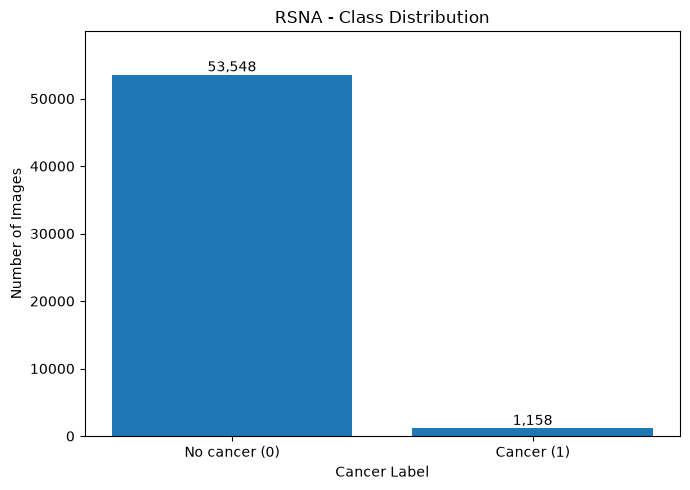

In [6]:
import matplotlib.pyplot as plt

# Nombre d'images par classe
class_counts = df["cancer"].value_counts().sort_index()

# Créer le graphique
plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["No cancer (0)", "Cancer (1)"],
    class_counts.values
)

# Afficher les nombres au-dessus des barres
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.title("RSNA - Class Distribution")
plt.xlabel("Cancer Label")
plt.ylabel("Number of Images")

plt.ylim(0, class_counts.max() * 1.12)
plt.tight_layout()
plt.show()

## Analyse des étiquettes à différents niveaux

Une patiente peut posséder plusieurs images et deux seins.
Nous allons distinguer les statistiques calculées au niveau
des images, des seins et des patientes.

In [7]:

# 1. Nombre total d'images
n_images = len(df)

# 2. Nombre de patientes distinctes
n_patientes = df["patient_id"].nunique()

# 3. Nombre de seins distincts
n_seins = df[["patient_id", "laterality"]].drop_duplicates().shape[0]

print("Nombre d'images :", n_images)
print("Nombre de patientes distinctes :", n_patientes)
print("Nombre de seins distincts :", n_seins)


Nombre d'images : 54706
Nombre de patientes distinctes : 11913
Nombre de seins distincts : 23826


In [8]:

# Regrouper les images par patient
patient_labels = df.groupby("patient_id")["cancer"].max()

# Compter les patients selon leur étiquette
patient_counts = patient_labels.value_counts().sort_index()

# Calculer les pourcentages
patient_percentages = (
    patient_labels.value_counts(normalize=True)
    .sort_index() * 100
)

# Créer un tableau récapitulatif
patient_summary = pd.DataFrame({
    "Number of patients": patient_counts,
    "Percentage (%)": patient_percentages.round(2)
})

display(patient_summary)


,Number of patients,Percentage (%)
cancer,,
0,11427,95.92
1,486,4.08


In [9]:
from sklearn.model_selection import train_test_split

# Une ligne par patient
patient_df = (
    df.groupby("patient_id")["cancer"]
    .max()
    .reset_index()
)

# Première séparation : 70 % train, 30 % temporaire
train_patients, temp_patients = train_test_split(
    patient_df,
    test_size=0.30,
    random_state=42,
    stratify=patient_df["cancer"]
)

# Deuxième séparation : 15 % validation, 15 % test
val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    random_state=42,
    stratify=temp_patients["cancer"]
)

print("Train :", len(train_patients))
print("Validation :", len(val_patients))
print("Test :", len(test_patients))

Train : 8339
Validation : 1787
Test : 1787


In [10]:
#Vérifir l'abscence de fuite de donnée
train_ids = set(train_patients["patient_id"])
val_ids = set(val_patients["patient_id"])
test_ids = set(test_patients["patient_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

In [11]:
train_df = df[df["patient_id"].isin(train_ids)].copy()
val_df = df[df["patient_id"].isin(val_ids)].copy()
test_df = df[df["patient_id"].isin(test_ids)].copy()

for name, subset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        name,
        "| Images :", len(subset),
        "| Patients :", subset["patient_id"].nunique(),
        "| Images positives :", subset["cancer"].sum()
    )

Train | Images : 38341 | Patients : 8339 | Images positives : 801
Validation | Images : 8184 | Patients : 1787 | Images positives : 180
Test | Images : 8181 | Patients : 1787 | Images positives : 177


In [12]:
from pathlib import Path

#Enregistrer les ensembles Train / Validation / Test
# Dossier de sortie
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Enregistrer les métadonnées de chaque ensemble
train_df.to_csv(output_dir / "train.csv", index=False)
val_df.to_csv(output_dir / "validation.csv", index=False)
test_df.to_csv(output_dir / "test.csv", index=False)

print("Les trois ensembles ont été enregistrés.")

Les trois ensembles ont été enregistrés.


In [13]:
from pathlib import Path
import pydicom

# Chemin vers notre première mammographie
image_path = Path(
    "../data/raw/train_images/10006/1459541791.dcm"
)

# Vérifier que le fichier existe
assert image_path.exists(), f"Fichier introuvable : {image_path}"

# Lire le fichier DICOM
dicom = pydicom.dcmread(image_path)

print("Fichier DICOM chargé avec succès !")
print("Dimensions :", dicom.Rows, "x", dicom.Columns)
print("Bits par pixel :", dicom.BitsAllocated)
print("Interprétation photométrique :", dicom.PhotometricInterpretation)
print("Format de compression :", dicom.file_meta.TransferSyntaxUID.name)

Fichier DICOM chargé avec succès !
Dimensions : 5355 x 4915
Bits par pixel : 16
Interprétation photométrique : MONOCHROME1
Format de compression : JPEG 2000 Image Compression (Lossless Only)


In [14]:
patient_info = df[
    (df["patient_id"] == 10006) &
    (df["image_id"] == 1459541791)
]

display(patient_info)

,site_id,patient_id,image_id,laterality,view,age,cancer,biopsy,invasive,BIRADS,implant,density,machine_id,difficult_negative_case
1,2,10006,1459541791,L,MLO,61.0,0,0,0,NaN,0,NaN,29,False


Dimensions : 5355 x 4915
Compression : JPEG 2000 Image Compression (Lossless Only)
Interprétation : MONOCHROME1
Shape : (5355, 4915)
Dtype : uint16
Min : 1489
Max : 3044


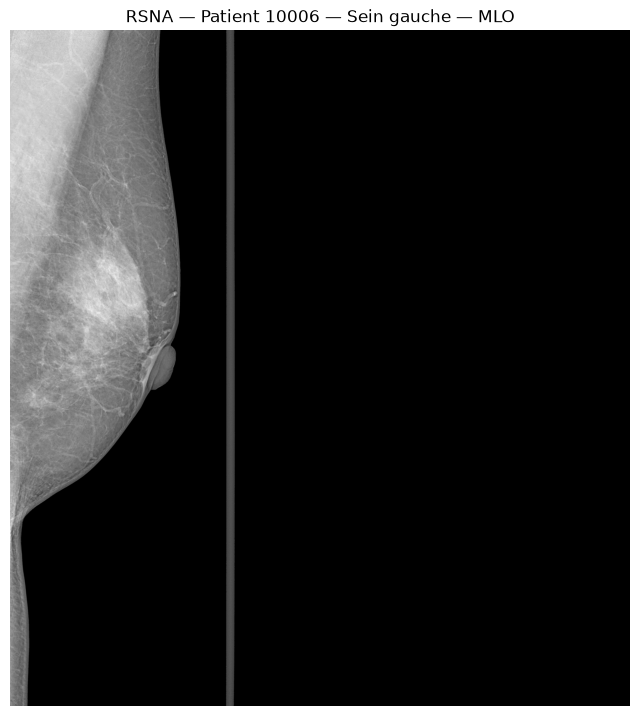

In [15]:
import pydicom
import numpy as np
import matplotlib.pyplot as plt

dicom = pydicom.dcmread(image_path)

print("Dimensions :", dicom.Rows, "x", dicom.Columns)
print("Compression :", dicom.file_meta.TransferSyntaxUID.name)
print("Interprétation :", dicom.PhotometricInterpretation)

image = dicom.pixel_array

print("Shape :", image.shape)
print("Dtype :", image.dtype)
print("Min :", image.min())
print("Max :", image.max())

display_image = image.astype(np.float32)

if dicom.PhotometricInterpretation == "MONOCHROME1":
    display_image = display_image.max() - display_image

plt.figure(figsize=(8, 10))
plt.imshow(display_image, cmap="gray")
plt.title("RSNA — Patient 10006 — Sein gauche — MLO")
plt.axis("off")
plt.show()

Shape : (5355, 4915)
Dtype : float32
Min : 0.0
Max : 1.0


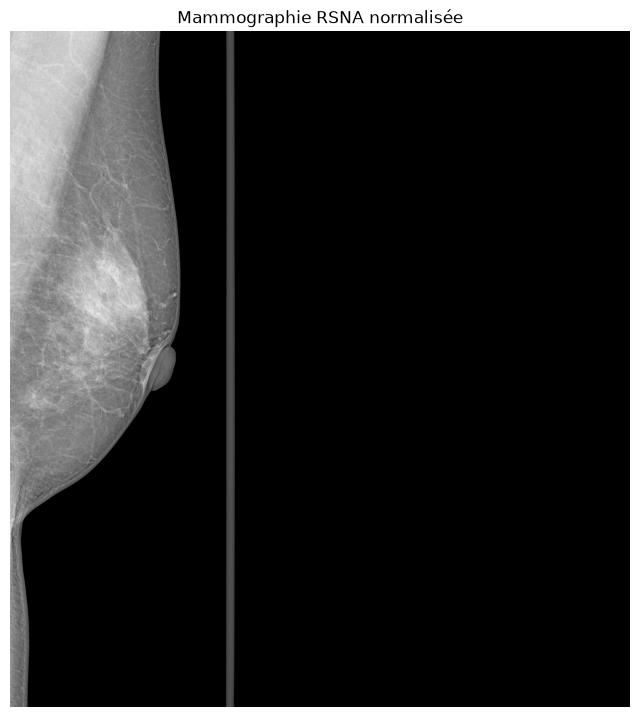

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Convertir en float32
image_float = image.astype(np.float32)

# 2. Inverser les niveaux de gris si nécessaire
if dicom.PhotometricInterpretation == "MONOCHROME1":
    image_float = image_float.max() - image_float

# 3. Normalisation min-max
min_val = image_float.min()
max_val = image_float.max()

if max_val > min_val:
    image_normalized = (
        (image_float - min_val) / (max_val - min_val)
    )
else:
    image_normalized = np.zeros_like(image_float)

# 4. Vérifier les résultats
print("Shape :", image_normalized.shape)
print("Dtype :", image_normalized.dtype)
print("Min :", image_normalized.min())
print("Max :", image_normalized.max())

# 5. Afficher l'image normalisée
plt.figure(figsize=(8, 10))
plt.imshow(image_normalized, cmap="gray", vmin=0, vmax=1)
plt.title("Mammographie RSNA normalisée")
plt.axis("off")
plt.show()

In [17]:
%pip install pillow

Note: you may need to restart the kernel to use updated packages.


Dimensions originales : (4915, 5355)
Dimensions réduites : (475, 518)


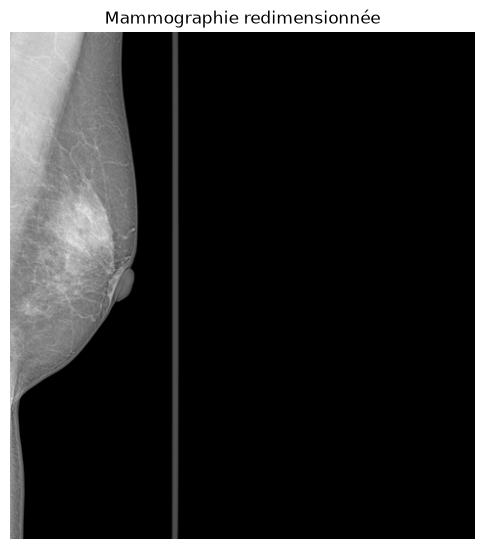

In [18]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Convertir les intensités normalisées en uint8
image_uint8 = (image_normalized * 255).round().astype(np.uint8)

# Créer une image Pillow
pil_image = Image.fromarray(image_uint8)

# Réduire l'image en conservant ses proportions
target_size = 518
resized_image = pil_image.copy()
resized_image.thumbnail(
    (target_size, target_size),
    Image.Resampling.LANCZOS
)

print("Dimensions originales :", pil_image.size)
print("Dimensions réduites :", resized_image.size)

plt.figure(figsize=(6, 7))
plt.imshow(resized_image, cmap="gray", vmin=0, vmax=255)
plt.title("Mammographie redimensionnée")
plt.axis("off")
plt.show()

In [34]:
# Convertir l'image réduite en RGB
rgb_image = resized_image.convert("RGB")

# Vérifier les caractéristiques
print("Mode :", rgb_image.mode)
print("Dimensions :", rgb_image.size)

# Convertir en tableau NumPy pour examiner les canaux
rgb_array = np.array(rgb_image)

print("Shape :", rgb_array.shape)

# Vérifier que les trois canaux sont identiques
print(
    "Canaux identiques :",
    np.array_equal(rgb_array[:, :, 0], rgb_array[:, :, 1])
    and np.array_equal(rgb_array[:, :, 1], rgb_array[:, :, 2])
)

Mode : RGB
Dimensions : (475, 518)
Shape : (518, 475, 3)
Canaux identiques : True


In [35]:
import torch
from transformers import AutoImageProcessor, AutoModel

# Choisir le GPU Apple Silicon si disponible
device = torch.device( "cpu")

print("Périphérique utilisé :", device)

# Modèle généraliste préentraîné
model_name = "facebook/dinov2-small"

# Charger le processeur d'images
processor = AutoImageProcessor.from_pretrained(model_name)

# Charger le modèle de fondation
model = AutoModel.from_pretrained(model_name)

# Placer le modèle sur le GPU ou CPU
model = model.to(device)

# Passer en mode évaluation
model.eval()

print("Modèle DINOv2 chargé avec succès !")
print("Dimension des embeddings :", model.config.hidden_size)

Périphérique utilisé : cpu


Loading weights: 100%|████████████████████| 223/223 [00:00<00:00, 19750.61it/s]

Modèle DINOv2 chargé avec succès !
Dimension des embeddings : 384


In [36]:
# Prétraitement avec le processeur DINOv2
inputs = processor(
    images=rgb_image,
    return_tensors="pt"
)

# Déplacer les tenseurs vers le même périphérique
inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

print("Dimensions du tenseur :", inputs["pixel_values"].shape)
print("Type :", inputs["pixel_values"].dtype)
print("Périphérique :", inputs["pixel_values"].device)

Dimensions du tenseur : torch.Size([1, 3, 224, 224])
Type : torch.float32
Périphérique : cpu


In [37]:
# Désactiver le calcul des gradients
with torch.inference_mode():

    # Faire passer l'image dans DINOv2
    outputs = model(**inputs)

    # Récupérer la représentation du token CLS
    embedding = outputs.last_hidden_state[:, 0, :]

# Convertir en tableau NumPy
embedding_numpy = embedding.cpu().numpy()

print("Dimensions de l'embedding :", embedding_numpy.shape)
print("Premières valeurs :", embedding_numpy[0, :10])

Dimensions de l'embedding : (1, 384)
Premières valeurs : [-0.42349553 -0.5523399   1.6582736   3.0663884  -4.4117727   0.05047546
 -2.2754307  -1.6552017  -1.5256202   3.0685794 ]


In [38]:
from pathlib import Path
import numpy as np

# Créer un dossier pour les embeddings DINOv2
output_dir = Path("../data/processed/embeddings/dinov2")
output_dir.mkdir(parents=True, exist_ok=True)

# Nom du fichier correspondant à notre mammographie
embedding_path = output_dir / "10006_1459541791.npy"

# Enregistrer le vecteur
np.save(embedding_path, embedding_numpy)

print("Embedding enregistré :", embedding_path)
print("Fichier existant :", embedding_path.exists())
print("Taille du fichier :", embedding_path.stat().st_size, "octets")

Embedding enregistré : ../data/processed/embeddings/dinov2/10006_1459541791.npy
Fichier existant : True
Taille du fichier : 1664 octets


In [39]:
# Recharger l'embedding enregistré
loaded_embedding = np.load(embedding_path)

print("Dimensions :", loaded_embedding.shape)
print("Type :", loaded_embedding.dtype)

# Vérifier que les valeurs sont identiques
print(
    "Valeurs identiques :",
    np.array_equal(embedding_numpy, loaded_embedding)
)

Dimensions : (1, 384)
Type : float32
Valeurs identiques : True


In [40]:
# Vérifier que les partitions existent
print("Train :", train_df.shape)
print("Validation :", val_df.shape)
print("Test :", test_df.shape)

# Vérifier les patients
train_ids = set(train_df["patient_id"])
val_ids = set(val_df["patient_id"])
test_ids = set(test_df["patient_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("Aucune fuite de patients détectée.")

Train : (38341, 14)
Validation : (8184, 14)
Test : (8181, 14)
Aucune fuite de patients détectée.


In [41]:
print("Nombre d'images par classe dans Train :")

print(
    train_df["cancer"]
    .value_counts()
    .sort_index()
)

print("\nNombre de patients par classe :")

print(
    train_df.groupby("patient_id")["cancer"]
    .max()
    .value_counts()
    .sort_index()
)

Nombre d'images par classe dans Train :
cancer
0    37540
1      801
Name: count, dtype: int64

Nombre de patients par classe :
cancer
0    7999
1     340
Name: count, dtype: int64


In [42]:
# Séparer les deux classes
negatives = train_df[train_df["cancer"] == 0]
positives = train_df[train_df["cancer"] == 1]

# Sélectionner 20 patients positifs distincts
positive_sample = (
    positives
    .sample(frac=1, random_state=42)
    .drop_duplicates(subset="patient_id")
    .head(20)
)

# Exclure ces patients du groupe négatif
negatives = negatives[
    ~negatives["patient_id"].isin(positive_sample["patient_id"])
]

# Sélectionner 20 patients négatifs distincts
negative_sample = (
    negatives
    .sample(frac=1, random_state=42)
    .drop_duplicates(subset="patient_id")
    .head(20)
)

# Réunir les deux classes
pilot_df = pd.concat(
    [positive_sample, negative_sample],
    ignore_index=True
)

# Mélanger les lignes
pilot_df = pilot_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Nombre d'images :", len(pilot_df))
print("Nombre de patients :", pilot_df["patient_id"].nunique())
print("\nRépartition des classes :")
print(pilot_df["cancer"].value_counts().sort_index())

assert len(pilot_df) == 40
assert pilot_df["patient_id"].nunique() == 40
assert pilot_df["cancer"].value_counts().to_dict() == {0: 20, 1: 20}


Nombre d'images : 40
Nombre de patients : 40

Répartition des classes :
cancer
0    20
1    20
Name: count, dtype: int64


In [43]:
from pathlib import Path

pilot_path = Path("../data/processed/pilot_40.csv")

pilot_df.to_csv(pilot_path, index=False)

print("Fichier enregistré :", pilot_path.exists())
print("Nombre de lignes :", len(pilot_df))

Fichier enregistré : True
Nombre de lignes : 40


In [44]:
pilot_df["dicom_path"] = pilot_df.apply(
    lambda row: (
        f"train_images/{int(row['patient_id'])}/"
        f"{int(row['image_id'])}.dcm"
    ),
    axis=1
)

display(
    pilot_df[
        ["patient_id", "image_id", "cancer", "dicom_path"]
    ].head(10)
)

,patient_id,image_id,cancer,dicom_path
0,4953,94584715,1,train_images/4953/94584715.dcm
1,55755,939219490,1,train_images/55755/939219490.dcm
2,38537,1655223848,1,train_images/38537/1655223848.dcm
3,20491,721584535,0,train_images/20491/721584535.dcm
4,14292,1404257623,1,train_images/14292/1404257623.dcm
5,3542,14104315,1,train_images/3542/14104315.dcm
6,39252,1107241837,0,train_images/39252/1107241837.dcm
7,65219,811335301,0,train_images/65219/811335301.dcm
8,14327,1878771430,0,train_images/14327/1878771430.dcm
9,36660,1456616206,1,train_images/36660/1456616206.dcm


In [46]:
from pathlib import Path
import pandas as pd

pilot_df = pd.read_csv("../data/processed/pilot_40.csv")

data_dir = Path("../data/raw")

# Construire le chemin local de chaque mammographie
pilot_df["local_path"] = pilot_df.apply(
    lambda row: (
        data_dir
        / "train_images"
        / str(int(row["patient_id"]))
        / f"{int(row['image_id'])}.dcm"
    ),
    axis=1
)

# Vérifier l'existence des fichiers
pilot_df["file_exists"] = pilot_df["local_path"].apply(
    lambda path: path.is_file() and path.stat().st_size > 0
)

print("Nombre total :", len(pilot_df))
print("Images disponibles :", pilot_df["file_exists"].sum())
print("Images manquantes :", (~pilot_df["file_exists"]).sum())

display(
    pilot_df[
        ["patient_id", "image_id", "cancer", "file_exists"]
    ].head(10)
)

assert pilot_df["file_exists"].all(), (
    "Certaines mammographies sont absentes ou vides."
)

Nombre total : 40
Images disponibles : 40
Images manquantes : 0


,patient_id,image_id,cancer,file_exists
0,4953,94584715,1,True
1,55755,939219490,1,True
2,38537,1655223848,1,True
3,20491,721584535,0,True
4,14292,1404257623,1,True
5,3542,14104315,1,True
6,39252,1107241837,0,True
7,65219,811335301,0,True
8,14327,1878771430,0,True
9,36660,1456616206,1,True


In [47]:
from pathlib import Path
import numpy as np
import pandas as pd

# Charger notre sélection de 40 mammographies
pilot_df = pd.read_csv("../data/processed/pilot_40.csv")

# Dossier contenant les embeddings DINOv2
embedding_dir = Path("../data/processed/embeddings/dinov2")

X_list = []
y_list = []
metadata = []

for _, row in pilot_df.iterrows():

    patient_id = int(row["patient_id"])
    image_id = int(row["image_id"])
    cancer = int(row["cancer"])

    embedding_path = (
        embedding_dir / f"{patient_id}_{image_id}.npy"
    )

    # Charger les 384 caractéristiques
    embedding = np.load(embedding_path)

    assert embedding.shape == (1, 384)
    assert np.isfinite(embedding).all()

    # Transformer (1, 384) en (384,)
    X_list.append(embedding.squeeze(0))

    # Conserver l'étiquette
    y_list.append(cancer)

    # Conserver les identifiants pour la traçabilité
    metadata.append({
        "patient_id": patient_id,
        "image_id": image_id,
        "cancer": cancer
    })

# Construire les tableaux NumPy
X = np.stack(X_list)
y = np.array(y_list)

metadata_df = pd.DataFrame(metadata)

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print("Répartition des classes :", np.bincount(y))
print("Nombre de patients :", metadata_df["patient_id"].nunique())

Dimensions de X : (40, 384)
Dimensions de y : (40,)
Répartition des classes : [20 20]
Nombre de patients : 40


In [48]:
output_dir = Path("../data/processed")

np.save(output_dir / "X_pilot_dinov2.npy", X)
np.save(output_dir / "y_pilot_dinov2.npy", y)

metadata_df.to_csv(
    output_dir / "metadata_pilot_dinov2.csv",
    index=False
)

print("Matrice X, étiquettes y et métadonnées enregistrées.")

Matrice X, étiquettes y et métadonnées enregistrées.


In [50]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# Charger X et y si nécessaire
import numpy as np

X = np.load("../data/processed/X_pilot_dinov2.npy")
y = np.load("../data/processed/y_pilot_dinov2.npy")

# Créer le pipeline
classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=42
    )
)

# Entraîner la régression logistique
classifier.fit(X, y)

# Prédire sur les mêmes données (test technique seulement)
y_pred = classifier.predict(X)

print("Accuracy sur les données d'entraînement :")
print(accuracy_score(y, y_pred))

print("\nMatrice de confusion :")
print(confusion_matrix(y, y_pred))

Accuracy sur les données d'entraînement :
1.0

Matrice de confusion :
[[20  0]
 [ 0 20]]


In [51]:
import pandas as pd

val_df = pd.read_csv("../data/processed/validation.csv")

print("Nombre total d'images :", len(val_df))

print("\nRépartition des images :")
print(val_df["cancer"].value_counts().sort_index())

print("\nRépartition des patients :")
print(
    val_df.groupby("patient_id")["cancer"]
    .max()
    .value_counts()
    .sort_index()
)


Nombre total d'images : 8184

Répartition des images :
cancer
0    8004
1     180
Name: count, dtype: int64

Répartition des patients :
cancer
0    1714
1      73
Name: count, dtype: int64


In [52]:
import pandas as pd

val_df = pd.read_csv("../data/processed/validation.csv")

# Séparer les deux classes
val_positive = val_df[val_df["cancer"] == 1]
val_negative = val_df[val_df["cancer"] == 0]

# Sélectionner 20 images positives de patients distincts
positive_sample = (
    val_positive
    .sample(frac=1, random_state=123)
    .drop_duplicates(subset="patient_id")
    .head(20)
)

# Éviter de reprendre un patient déjà sélectionné
val_negative = val_negative[
    ~val_negative["patient_id"].isin(positive_sample["patient_id"])
]

# Sélectionner 20 images négatives de patients distincts
negative_sample = (
    val_negative
    .sample(frac=1, random_state=123)
    .drop_duplicates(subset="patient_id")
    .head(20)
)

# Construire le jeu pilote de validation
val_pilot_df = pd.concat(
    [positive_sample, negative_sample],
    ignore_index=True
)

val_pilot_df = val_pilot_df.sample(
    frac=1,
    random_state=123
).reset_index(drop=True)

# Vérifications
print("Nombre d'images :", len(val_pilot_df))
print("Nombre de patients :", val_pilot_df["patient_id"].nunique())

print("\nRépartition des classes :")
print(val_pilot_df["cancer"].value_counts().sort_index())

# Vérifier qu'aucun patient ne se retrouve dans les deux partitions
train_df = pd.read_csv("../data/processed/train.csv")

assert set(val_pilot_df["patient_id"]).isdisjoint(
    set(train_df["patient_id"])
)

assert len(val_pilot_df) == 40
assert val_pilot_df["patient_id"].nunique() == 40

# Enregistrer la sélection
val_pilot_df.to_csv(
    "../data/processed/validation_pilot_40.csv",
    index=False
)

print("\nSélection de validation enregistrée.")

Nombre d'images : 40
Nombre de patients : 40

Répartition des classes :
cancer
0    20
1    20
Name: count, dtype: int64

Sélection de validation enregistrée.


In [1]:
import pandas as pd

results_df = pd.DataFrame({
    "patient_id": val_pilot_df["patient_id"],
    "image_id": val_pilot_df["image_id"],
    "cancer_reel": y_val,
    "probabilite_cancer": y_val_proba,
    "prediction": y_val_pred
})

results_df["correct"] = (
    results_df["cancer_reel"] == results_df["prediction"]
)

print("Résumé des probabilités par classe réelle :")

print(
    results_df.groupby("cancer_reel")["probabilite_cancer"]
    .describe()
    .round(3)
)

print("\nNombre de prédictions positives :")
print((results_df["prediction"] == 1).sum())

NameError: name 'val_pilot_df' is not defined